In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

log = []
def record(step, action, reason):
    log.append({"step": step, "action": action, "reason": reason})

In [2]:
squares = [x**2 for x in range(6)]                 # list comprehension
person  = {"name": "Keshav", "skills": ["python", "ml"]}   # dict
def zscore(v, mean, std):                         
    return (v - mean) / std
print(squares, person["skills"], zscore(10, 5, 2))

a = np.array([[1, 2, 3], [4, 5, 6]])
print("shape:", a.shape, "| mean per column:", a.mean(axis=0))
print("broadcasting:", a + np.array([10, 20, 30]))    # vector added to every row
print("boolean mask:", a[a > 3])                      # filtering without loops
print("NaN-aware mean:", np.nanmean(np.array([1, np.nan, 3])))

df_demo = pd.DataFrame({"x": [1, 2, 3, 4], "g": ["a", "a", "b", "b"]})
print(df_demo[df_demo.x > 2])                        # row filtering
print(df_demo.groupby("g")["x"].mean())             

[0, 1, 4, 9, 16, 25] ['python', 'ml'] 2.5
shape: (2, 3) | mean per column: [2.5 3.5 4.5]
broadcasting: [[11 22 33]
 [14 25 36]]
boolean mask: [4 5 6]
NaN-aware mean: 2.0
   x  g
2  3  b
3  4  b
g
a    1.5
b    3.5
Name: x, dtype: float64


In [3]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("titanic.csv")  

raw = df.copy()  
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nMissing %:")
print((df.isna().mean() * 100).round(1)[df.isna().any()])
print("\nDuplicate rows:", df.duplicated().sum())
df.describe(include="all").T

Missing values per column:
Age         177
Cabin       687
Embarked      2
dtype: int64

Missing %:
Age         19.9
Cabin       77.1
Embarked     0.2
dtype: float64

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


**Observations**
- `Age` ~20% missing, `Cabin` ~77% missing, `Embarked` has 2 missing.
- `PassengerId`, `Name`, `Ticket` are identifiers / free text, not directly usable as features.
- `Sex`, `Embarked` are categorical strings; `Pclass` is numeric but really ordinal/categorical.
- `Fare` looks right-skewed (mean >> median).

## 3. Data cleaning

### 3.1 Duplicates

In [6]:
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows")
record("Duplicates", f"Dropped {before - len(df)} duplicate rows", "Duplicates bias the model toward repeated samples")

Removed 0 duplicate rows


In [7]:
# Cabin -> binary indicator
df["HasCabin"] = df["Cabin"].notna().astype(int)
df = df.drop(columns="Cabin")
record("Missing: Cabin", "Created HasCabin flag, dropped Cabin", "77% missing; presence carries signal")

# Embarked -> mode
mode_emb = df["Embarked"].mode()[0]
df["Embarked"] = df["Embarked"].fillna(mode_emb)
record("Missing: Embarked", f"Filled 2 NaN with mode '{mode_emb}'", "Very few missing, categorical")

# Age -> group median
df["Age_missing"] = df["Age"].isna().astype(int)     # keep a flag so the model knows it was imputed
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))
record("Missing: Age", "Filled with median by (Pclass, Sex); added Age_missing flag", "Group median is more accurate than global; flag preserves missingness signal")

print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


### 3.3 Outliers (IQR rule)
Values outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]` are flagged. For `Fare`, the high values are real (first-class tickets), so we **don't delete** them. We tame the skew with a log transform instead.

Age: bounds=(-0.2, 57.8) -> 33 outliers
Fare: bounds=(-26.7, 65.6) -> 116 outliers


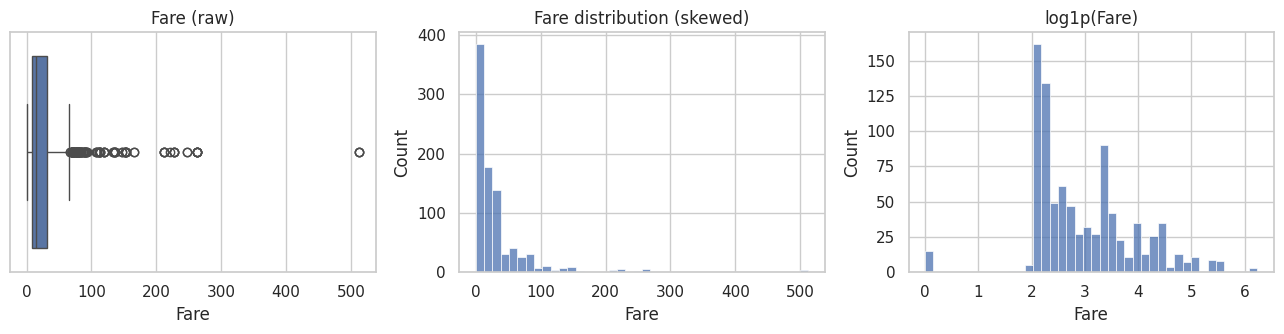

In [8]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["Age", "Fare"]:
    lo, hi = iqr_bounds(df[col])
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: bounds=({lo:.1f}, {hi:.1f}) -> {n} outliers")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
sns.boxplot(x=df["Fare"], ax=ax[0]).set_title("Fare (raw)")
sns.histplot(df["Fare"], ax=ax[1], bins=40).set_title("Fare distribution (skewed)")
sns.histplot(np.log1p(df["Fare"]), ax=ax[2], bins=40).set_title("log1p(Fare)")
plt.tight_layout(); plt.show()

In [9]:
df["Fare_log"] = np.log1p(df["Fare"])     # log1p handles Fare = 0 safely
record("Outliers: Fare", "Kept outliers, added Fare_log = log1p(Fare)", "High fares are genuine; log reduces skew without losing data")

## 4. Feature engineering & selection
### 4.1 Engineering
- `Title` extracted from `Name` (Mr, Mrs, Miss, Master...). Rare titles grouped into `Rare`.
- `FamilySize = SibSp + Parch + 1` and `IsAlone`.

In [10]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
df["Title"] = df["Title"].replace(title_map)
common = ["Mr", "Mrs", "Miss", "Master"]
df["Title"] = df["Title"].where(df["Title"].isin(common), "Rare")

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

record("Feature engineering", "Added Title (from Name), FamilySize, IsAlone", "Extract signal from text / combine related columns")
print(df["Title"].value_counts())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


### 4.2 Feature selection
Drop columns that are identifiers or now redundant, then check correlations among numeric features to avoid redundant ones.

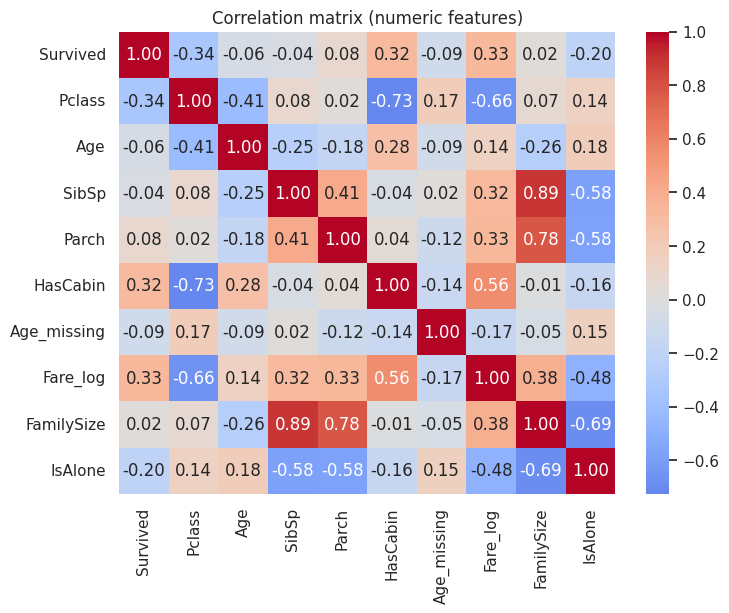

In [11]:
drop_cols = ["PassengerId", "Name", "Ticket", "Fare"]   # ids/text, and raw Fare (replaced by Fare_log)
df = df.drop(columns=drop_cols)
record("Feature selection", f"Dropped {drop_cols}", "Identifiers carry no generalizable signal; Fare replaced by Fare_log")

num = df.select_dtypes("number")
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)"); plt.show()

`SibSp`, `Parch` and `FamilySize` are strongly related (FamilySize is built from the other two). To avoid redundancy we keep `FamilySize` + `IsAlone` and drop `SibSp`/`Parch`. `Pclass` and `Fare_log` correlate (about -0.66), which is expected but not enough to drop either.

In [12]:
df = df.drop(columns=["SibSp", "Parch"])
record("Feature selection", "Dropped SibSp, Parch", "Redundant with FamilySize")
df.head()

,Survived,Pclass,Sex,Age,Embarked,HasCabin,Age_missing,Fare_log,Title,FamilySize,IsAlone
0,0,3,male,22.0,S,0,0,2.110213,Mr,2,0
1,1,1,female,38.0,C,1,0,4.280593,Mrs,2,0
2,1,3,female,26.0,S,0,0,2.188856,Miss,1,1
3,1,1,female,35.0,S,1,0,3.990834,Mrs,2,0
4,0,3,male,35.0,S,0,0,2.202765,Mr,1,1


## 5. Encoding categorical variables


In [13]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked", "Title"], drop_first=True, dtype=int)
record("Encoding", "Sex -> 0/1; one-hot (drop_first) for Embarked, Title; Pclass kept ordinal", "Models need numeric input; one-hot avoids fake ordering on nominal data")
print(df.dtypes)
df.head()

Survived         int64
Pclass           int64
Sex              int64
Age            float64
HasCabin         int64
Age_missing      int64
Fare_log       float64
FamilySize       int64
IsAlone          int64
Embarked_Q       int64
Embarked_S       int64
Title_Miss       int64
Title_Mr         int64
Title_Mrs        int64
Title_Rare       int64
dtype: object


,Survived,Pclass,Sex,Age,HasCabin,Age_missing,Fare_log,FamilySize,IsAlone,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,0,0,2.110213,2,0,0,1,0,1,0,0
1,1,1,1,38.0,1,0,4.280593,2,0,0,0,0,0,1,0
2,1,3,1,26.0,0,0,2.188856,1,1,0,1,1,0,0,0
3,1,1,1,35.0,1,0,3.990834,2,0,0,1,0,0,1,0
4,0,3,0,35.0,0,0,2.202765,1,1,0,1,0,1,0,0


## 6. Split, then normalize


In [14]:
X = df.drop(columns="Survived")
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   

scale_cols = ["Age", "Fare_log", "FamilySize"]
scaler = StandardScaler().fit(X_train[scale_cols])     

X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_s[scale_cols]  = scaler.transform(X_test[scale_cols])

record("Split", "80/20 stratified split, random_state=42", "Hold out data to evaluate honestly")
record("Normalization", f"StandardScaler on {scale_cols}, fit on train only", "Puts features on comparable scale; avoids leakage")

print("Train mean (should be ~0):", X_train_s[scale_cols].mean().round(3).to_dict())
print("Train std  (should be ~1):", X_train_s[scale_cols].std().round(3).to_dict())
print("Test  mean (close to 0, not exact):", X_test_s[scale_cols].mean().round(3).to_dict())

Train mean (should be ~0): {'Age': 0.0, 'Fare_log': 0.0, 'FamilySize': 0.0}
Train std  (should be ~1): {'Age': 1.001, 'Fare_log': 1.001, 'FamilySize': 1.001}
Test  mean (close to 0, not exact): {'Age': -0.065, 'Fare_log': 0.058, 'FamilySize': 0.066}


In [15]:
mm = MinMaxScaler().fit(X_train[scale_cols])
print(pd.DataFrame(mm.transform(X_train[scale_cols]), columns=scale_cols).describe().loc[["min", "max"]])

     Age  Fare_log  FamilySize
min  0.0       0.0         0.0
max  1.0       1.0         1.0


## 7. Exploratory Data Analysis
Done on the cleaned (pre-scaling) data so values stay interpretable.

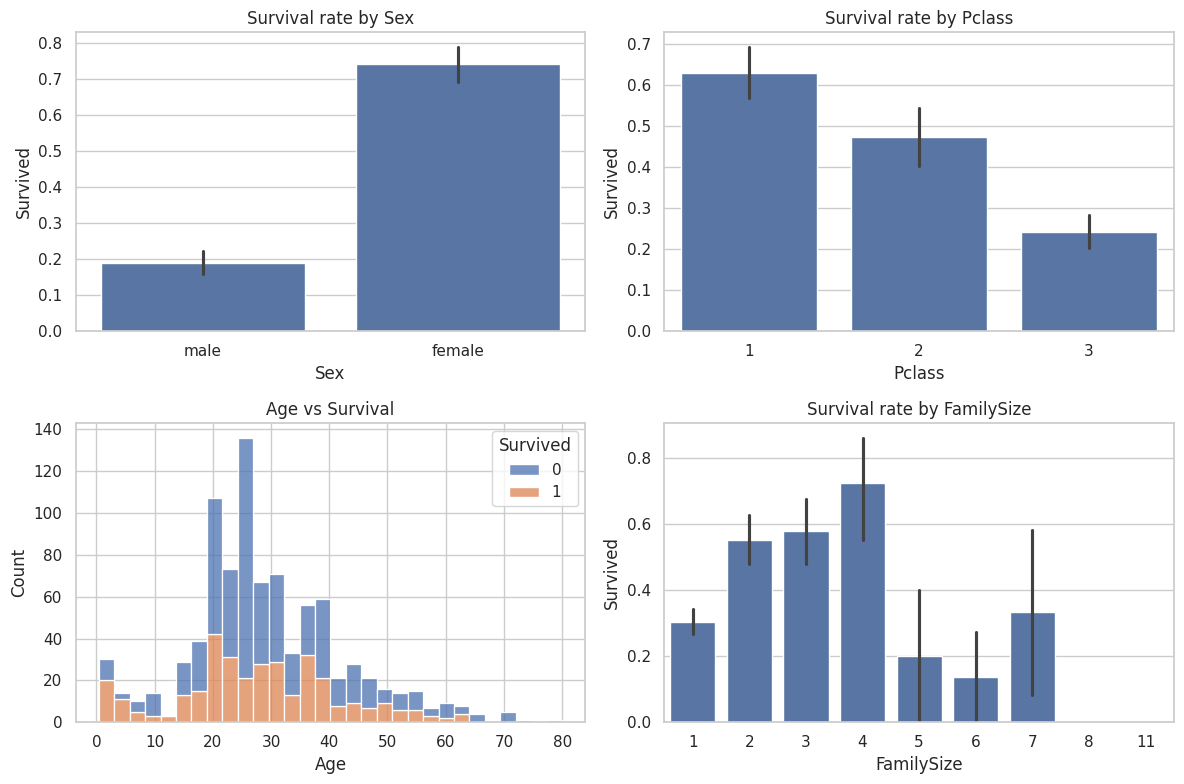

In [16]:
eda = raw.drop_duplicates().copy()   # use raw labels (Sex, Pclass etc.) for readable plots
eda["Age"] = eda["Age"].fillna(eda.groupby(["Pclass", "Sex"])["Age"].transform("median"))

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.barplot(data=eda, x="Sex", y="Survived", ax=ax[0, 0]).set_title("Survival rate by Sex")
sns.barplot(data=eda, x="Pclass", y="Survived", ax=ax[0, 1]).set_title("Survival rate by Pclass")
sns.histplot(data=eda, x="Age", hue="Survived", bins=30, multiple="stack", ax=ax[1, 0]).set_title("Age vs Survival")
sns.barplot(data=df, x="FamilySize", y="Survived", ax=ax[1, 1]).set_title("Survival rate by FamilySize")
plt.tight_layout(); plt.show()

In [17]:
print("Survival rate overall:", round(df["Survived"].mean(), 3))
print()
print(eda.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean").round(2))

Survival rate overall: 0.384

Sex     female  male
Pclass              
1         0.97  0.37
2         0.92  0.16
3         0.50  0.14


**Key findings**
- Women survived at roughly 4x the rate of men. `Sex` is the single strongest predictor.
- Survival falls sharply with passenger class (1st >> 3rd).
- Children (low Age) had a higher survival rate.
- Very large families did worse; solo travellers and small families did better. This is why `FamilySize` was worth engineering.
- Classes are imbalanced (~38% survived), which is why we stratified the split.

## 8. Before vs After, log & save

In [18]:
summary = pd.DataFrame({
    "Before": [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), int(raw.select_dtypes(exclude="number").shape[1])],
    "After":  [df.shape[0],  df.shape[1],  int(df.isna().sum().sum()),  int(df.select_dtypes(exclude="number").shape[1])],
}, index=["Rows", "Columns", "Missing cells", "Text columns"])
summary

,Before,After
Rows,891,891
Columns,12,15
Missing cells,866,0
Text columns,5,0


In [19]:
log_df = pd.DataFrame(log)
log_df.index = log_df.index + 1
pd.set_option("display.max_colwidth", 120)
log_df

,step,action,reason
1,Duplicates,Dropped 0 duplicate rows,Duplicates bias the model toward repeated samples
2,Missing: Cabin,"Created HasCabin flag, dropped Cabin",77% missing; presence carries signal
3,Missing: Embarked,Filled 2 NaN with mode 'S',"Very few missing, categorical"
4,Missing: Age,"Filled with median by (Pclass, Sex); added Age_missing flag",Group median is more accurate than global; flag preserves missingness signal
5,Outliers: Fare,"Kept outliers, added Fare_log = log1p(Fare)",High fares are genuine; log reduces skew without losing data
6,Feature engineering,"Added Title (from Name), FamilySize, IsAlone",Extract signal from text / combine related columns
7,Feature selection,"Dropped ['PassengerId', 'Name', 'Ticket', 'Fare']",Identifiers carry no generalizable signal; Fare replaced by Fare_log
8,Feature selection,"Dropped SibSp, Parch",Redundant with FamilySize
9,Encoding,"Sex -> 0/1; one-hot (drop_first) for Embarked, Title; Pclass kept ordinal",Models need numeric input; one-hot avoids fake ordering on nominal data
10,Split,"80/20 stratified split, random_state=42",Hold out data to evaluate honestly


In [20]:
df.to_csv("titanic_cleaned.csv", index=False)
log_df.to_csv("preprocessing_log.csv", index_label="#")
X_train_s.assign(Survived=y_train).to_csv("titanic_train_scaled.csv", index=False)
X_test_s.assign(Survived=y_test).to_csv("titanic_test_scaled.csv", index=False)
print("Saved: titanic_cleaned.csv, preprocessing_log.csv, titanic_train_scaled.csv, titanic_test_scaled.csv")

Saved: titanic_cleaned.csv, preprocessing_log.csv, titanic_train_scaled.csv, titanic_test_scaled.csv
